# Notebook 06: Global Conformal Prediction & Scoring Mechanics (Phase 3A)

- **Objective**: Objective 3 — Uncertainty-Aware Classification via Inductive Conformal Prediction
- **Purpose**: Apply split conformal prediction using MAPIE to transform point predictions from baseline classifiers (`RandomForest`, `XGBoost`) into mathematically guaranteed prediction sets. Compare two major non-conformity scoring algorithms:
  1. **LAC (Least Ambiguous Classifier)**: Probability margin non-conformity ($1 - \hat{P}(y|x)$).
  2. **APS (Adaptive Prediction Sets)**: Cumulative softmax score (Romano et al., 2020).
- **Core Medical Discovery**: Evaluate marginal vs. conditional coverage. Demonstrate the **minority under-coverage trap** — proving empirically that while global conformal prediction achieves the nominal 90% guarantee on average, the high-stakes **Pathological** class suffers from severe under-coverage because the dominant **Normal** class inflates the overall average.
- **Golden Rule Compliance**: The model was trained on `Train` ($N=1,275$). Conformalization is performed strictly on `Calibration` ($N=425$). Evaluation is reported once on `Test` ($N=426$).
- **Outputs**:
  1. Empirical coverage & set size efficiency tables across significance levels $\alpha \in [0.01, 0.25]$.
  2. Prediction set composition breakdown (Empty vs. Singleton vs. Multi-class sets).
  3. Per-class coverage comparison showing the minority gap.
  4. Publication-grade 4-panel figure saved to `reports/figures/global_conformal_comparison.png`.

In [1]:
import sys
from pathlib import Path

# Ensure project root is in sys.path
PROJECT_ROOT = Path(".").resolve()
if not (PROJECT_ROOT / "src").exists():
    PROJECT_ROOT = Path("..").resolve()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from src.data.load import load_data
from src.data.split import split_data
from src.conformal.global_cp import (
    fit_global_conformal_classifier,
    predict_prediction_sets,
    evaluate_conformal_coverage,
    sweep_alpha_conformal,
    plot_global_conformal_comparison,
    CLASS_NAMES_DEFAULT
)

print("[OK] Environment loaded successfully with MAPIE & Conformal modules.")

[OK] Environment loaded successfully with MAPIE & Conformal modules.


## 1. Conformal Prediction: Theoretical Background

Standard ML models force an argmax decision: $\hat{y} = \arg\max_{k} \hat{P}(Y=k \mid X)$. In ambiguous fetal monitoring, a forced single choice can be fatal if the baby is Pathological but mislabeled as Normal.

### Split Conformal Prediction Framework (Vovk et al., 2005)
Given calibration data $\{(X_i, Y_i)\}_{i=1}^{n_{\text{cal}}}$ and a significance level $\alpha \in (0, 1)$ (e.g., $\alpha = 0.10$ for 90% confidence):
1. Define a **non-conformity score** $s(x, y)$ that measures how unusual label $y$ is given features $x$.
2. Compute calibration non-conformity scores on the true labels: $S_i = s(X_i, Y_i)$ for $i = 1, \dots, n_{\text{cal}}$.
3. Compute the empirical $(1 - \alpha)$-quantile:
   $$\hat{q} = \text{Quantile}\left(\frac{\lceil (n_{\text{cal}} + 1)(1 - \alpha) \rceil}{n_{\text{cal}}}, \{S_i\}_{i=1}^{n_{\text{cal}}}\right)$$
4. For a new test patient $X_{n+1}$, output the prediction set:
   $$\Gamma_{1-\alpha}(X_{n+1}) = \{y \in \mathcal{Y} : s(X_{n+1}, y) \le \hat{q}\}$$

**Marginal Guarantee**:
$$P(Y_{n+1} \in \Gamma_{1-\alpha}(X_{n+1})) \ge 1 - \alpha$$

### Two Scoring Algorithms Evaluated in Phase 3A:
1. **LAC (Least Ambiguous Classifier / Sadinle et al., 2019)**:
   $$s_{\text{LAC}}(x, y) = 1 - \hat{P}(Y=y \mid X=x)$$
   Sets include all classes whose estimated probability is at least $1 - \hat{q}$. It produces small sets but can output empty sets $\emptyset$ if the model is extremely uncertain.

2. **APS (Adaptive Prediction Sets / Romano et al., 2020)**:
   Classes are sorted by descending predicted probability: $\hat{\pi}_1(x) \ge \hat{\pi}_2(x) \ge \dots \ge \hat{\pi}_K(x)$. The score sums cumulative probabilities until the true class is reached:
   $$s_{\text{APS}}(x, y) = \sum_{k=1}^{r(x, y)} \hat{\pi}_k(x) + U \cdot \hat{\pi}_{r(x, y)}(x)$$
   APS guarantees non-empty prediction sets and adapts set sizes dynamically to local difficulty.

## 2. Load Data & Partitions

We load the CTG dataset and perform the exact stratified 60/20/20 split (`random_state=42`).

In [2]:
df = load_data(PROJECT_ROOT / "data/raw/fetal_health.csv")
X_train, X_cal, X_test, y_train, y_cal, y_test = split_data(df, random_state=42)

print(f"\nPartition Summary:")
print(f"  Train Set (fit base model):        {len(X_train)} samples ({len(X_train)/len(df):.1%})")
print(f"  Calibration Set (conformalize):    {len(X_cal)} samples ({len(X_cal)/len(df):.1%})")
print(f"  Test Set (final evaluation):       {len(X_test)} samples ({len(X_test)/len(df):.1%})")

# Check class distribution in test set
test_dist = pd.DataFrame({
    'Class': [1.0, 2.0, 3.0],
    'Name': ['Normal', 'Suspect', 'Pathological'],
    'Count': [(y_test == c).sum() for c in [1.0, 2.0, 3.0]],
    'Percentage': [(y_test == c).mean() * 100 for c in [1.0, 2.0, 3.0]]
})
print("\nTest Set Class Distribution:")
print(test_dist.to_string(index=False))

[src.data.load] Dataset loaded successfully from 'D:\Desktop\PROJECTS\Fetal-Health-Uncertainity\data\raw\fetal_health.csv'. Shape: (2126, 22)
[src.data.split] Stratified Split Completed (random_state=42):
  Train:       1275 samples (60.0%)
  Calibration: 425 samples (20.0%)
  Test:        426 samples (20.0%)

Partition Summary:
  Train Set (fit base model):        1275 samples (60.0%)
  Calibration Set (conformalize):    425 samples (20.0%)
  Test Set (final evaluation):       426 samples (20.0%)

Test Set Class Distribution:
 Class         Name  Count  Percentage
   1.0       Normal    332   77.934272
   2.0      Suspect     59   13.849765
   3.0 Pathological     35    8.215962


## 3. Load Pre-trained Base Model

We load the pre-trained `RandomForestClassifier` (and can also benchmark `XGBClassifier`) saved in `models/`.

In [3]:
models_dir = PROJECT_ROOT / "models"
base_model = joblib.load(models_dir / "random_forest.joblib")
classes = base_model.classes_

print(f"[Loaded] Base Estimator: {type(base_model).__name__}")
print(f"[Loaded] Classes: {classes} -> {CLASS_NAMES_DEFAULT}")

[Loaded] Base Estimator: RandomForestClassifier
[Loaded] Classes: [1. 2. 3.] -> {1.0: 'Normal', 2.0: 'Suspect', 3.0: 'Pathological'}


## 4. Implement Global LAC Conformal Prediction (Target: 90% Confidence, $\alpha = 0.10$)

We fit (conformalize) the Least Ambiguous Classifier on `(X_cal, y_cal)` and evaluate on `X_test`.

In [4]:
cp_lac_90 = fit_global_conformal_classifier(
    estimator=base_model,
    X_cal=X_cal,
    y_cal=y_cal,
    method="lac",
    confidence_level=0.90,
    random_state=42
)

y_pred_lac, y_ps_lac = predict_prediction_sets(cp_lac_90, X_test)
metrics_lac_90 = evaluate_conformal_coverage(y_test, y_ps_lac, classes=classes)

print("====================================================")
print("           GLOBAL LAC RESULTS (Target 90%)           ")
print("====================================================")
print(f"Overall Marginal Coverage:   {metrics_lac_90['marginal_coverage']:.2%} (Nominal target: 90.0%)")
print(f"Average Prediction Set Size: {metrics_lac_90['avg_set_size']:.3f} labels")
print("\nPer-Class Coverage Breakdown:")
for c_name, cov in metrics_lac_90['per_class_coverage'].items():
    size = metrics_lac_90['per_class_avg_set_size'][c_name]
    print(f"  - {c_name:15s}: Coverage = {cov:.2%}, Avg Set Size = {size:.3f}")

print("\nPrediction Set Composition:")
print(f"  - Empty Sets (|S|=0):      {metrics_lac_90['empty_set_pct']:.2f}%")
print(f"  - Singleton Sets (|S|=1):  {metrics_lac_90['singleton_set_pct']:.2f}%")
print(f"  - Multi-class Sets (|S|>=2): {metrics_lac_90['multi_class_set_pct']:.2f}%")

           GLOBAL LAC RESULTS (Target 90%)           
Overall Marginal Coverage:   89.91% (Nominal target: 90.0%)
Average Prediction Set Size: 0.944 labels

Per-Class Coverage Breakdown:
  - Normal         : Coverage = 96.99%, Avg Set Size = 0.976
  - Suspect        : Coverage = 57.63%, Avg Set Size = 0.831
  - Pathological   : Coverage = 77.14%, Avg Set Size = 0.829

Prediction Set Composition:
  - Empty Sets (|S|=0):      5.63%
  - Singleton Sets (|S|=1):  94.37%
  - Multi-class Sets (|S|>=2): 0.00%


## 5. Implement Global APS Conformal Prediction (Target: 90% Confidence, $\alpha = 0.10$)

Next, we evaluate Adaptive Prediction Sets (APS) under the identical split.

In [5]:
cp_aps_90 = fit_global_conformal_classifier(
    estimator=base_model,
    X_cal=X_cal,
    y_cal=y_cal,
    method="aps",
    confidence_level=0.90,
    random_state=42
)

y_pred_aps, y_ps_aps = predict_prediction_sets(cp_aps_90, X_test)
metrics_aps_90 = evaluate_conformal_coverage(y_test, y_ps_aps, classes=classes)

print("====================================================")
print("           GLOBAL APS RESULTS (Target 90%)           ")
print("====================================================")
print(f"Overall Marginal Coverage:   {metrics_aps_90['marginal_coverage']:.2%} (Nominal target: 90.0%)")
print(f"Average Prediction Set Size: {metrics_aps_90['avg_set_size']:.3f} labels")
print("\nPer-Class Coverage Breakdown:")
for c_name, cov in metrics_aps_90['per_class_coverage'].items():
    size = metrics_aps_90['per_class_avg_set_size'][c_name]
    print(f"  - {c_name:15s}: Coverage = {cov:.2%}, Avg Set Size = {size:.3f}")

print("\nPrediction Set Composition:")
print(f"  - Empty Sets (|S|=0):      {metrics_aps_90['empty_set_pct']:.2f}%")
print(f"  - Singleton Sets (|S|=1):  {metrics_aps_90['singleton_set_pct']:.2f}%")
print(f"  - Multi-class Sets (|S|>=2): {metrics_aps_90['multi_class_set_pct']:.2f}%")

           GLOBAL APS RESULTS (Target 90%)           
Overall Marginal Coverage:   99.30% (Nominal target: 90.0%)
Average Prediction Set Size: 1.289 labels

Per-Class Coverage Breakdown:
  - Normal         : Coverage = 100.00%, Avg Set Size = 1.148
  - Suspect        : Coverage = 94.92%, Avg Set Size = 1.864
  - Pathological   : Coverage = 100.00%, Avg Set Size = 1.657

Prediction Set Composition:
  - Empty Sets (|S|=0):      0.00%
  - Singleton Sets (|S|=1):  74.88%
  - Multi-class Sets (|S|>=2): 25.12%


## 6. Inspect Real Clinical Examples from the Test Set

Let's see how conformal prediction sets behave on actual test patient records.

In [6]:
ps_lac_2d = y_ps_lac[:, :, 0] if y_ps_lac.ndim == 3 else y_ps_lac
ps_aps_2d = y_ps_aps[:, :, 0] if y_ps_aps.ndim == 3 else y_ps_aps

sample_rows = []
for i in range(12):
    true_label = CLASS_NAMES_DEFAULT[y_test.iloc[i]]
    pred_label = CLASS_NAMES_DEFAULT[y_pred_lac[i]]
    lac_set = [CLASS_NAMES_DEFAULT[classes[k]] for k in range(3) if ps_lac_2d[i, k]]
    aps_set = [CLASS_NAMES_DEFAULT[classes[k]] for k in range(3) if ps_aps_2d[i, k]]
    
    sample_rows.append({
        'Index': i,
        'True Label': true_label,
        'Argmax Pred': pred_label,
        'LAC Set (90%)': lac_set,
        'APS Set (90%)': aps_set,
        'LAC Covered?': true_label in lac_set,
        'APS Covered?': true_label in aps_set
    })

df_samples = pd.DataFrame(sample_rows)
print("Sample Test Predictions with Conformal Sets:")
print(df_samples.to_string(index=False))

Sample Test Predictions with Conformal Sets:
 Index   True Label  Argmax Pred  LAC Set (90%)          APS Set (90%)  LAC Covered?  APS Covered?
     0       Normal       Normal       [Normal]               [Normal]          True          True
     1      Suspect       Normal       [Normal]      [Normal, Suspect]         False          True
     2       Normal      Suspect             []      [Normal, Suspect]         False          True
     3       Normal       Normal       [Normal]               [Normal]          True          True
     4      Suspect Pathological [Pathological] [Normal, Pathological]         False         False
     5       Normal       Normal       [Normal]               [Normal]          True          True
     6 Pathological Pathological             [] [Normal, Pathological]         False          True
     7       Normal       Normal       [Normal]               [Normal]          True          True
     8       Normal       Normal       [Normal]               [N

## 7. Multi-$\alpha$ Significance Sweep (Coverage vs. Efficiency Trade-off)

To thoroughly benchmark both algorithms, we sweep $\alpha \in [0.01, 0.25]$ corresponding to confidence levels $1 - \alpha \in [75\%, 99\%]$.

In [7]:
alphas = [0.01, 0.02, 0.05, 0.10, 0.15, 0.20, 0.25]

print("Running alpha sweep for LAC...")
df_lac_sweep = sweep_alpha_conformal(base_model, X_cal, y_cal, X_test, y_test, method="lac", alphas=alphas)

print("Running alpha sweep for APS...")
df_aps_sweep = sweep_alpha_conformal(base_model, X_cal, y_cal, X_test, y_test, method="aps", alphas=alphas)

print("\n--- LAC Alpha Sweep Table ---")
print(df_lac_sweep[['alpha', 'target_confidence', 'empirical_coverage', 'avg_set_size', 'cov_Normal', 'cov_Suspect', 'cov_Pathological', 'empty_pct', 'singleton_pct', 'multi_pct']].to_string(index=False))

print("\n--- APS Alpha Sweep Table ---")
print(df_aps_sweep[['alpha', 'target_confidence', 'empirical_coverage', 'avg_set_size', 'cov_Normal', 'cov_Suspect', 'cov_Pathological', 'empty_pct', 'singleton_pct', 'multi_pct']].to_string(index=False))

Running alpha sweep for LAC...
Running alpha sweep for APS...

--- LAC Alpha Sweep Table ---
 alpha  target_confidence  empirical_coverage  avg_set_size  cov_Normal  cov_Suspect  cov_Pathological  empty_pct  singleton_pct  multi_pct
  0.01               0.99              0.9906        1.2535      1.0000       0.9322            1.0000       0.00          77.93      22.07
  0.02               0.98              0.9812        1.1808      1.0000       0.8814            0.9714       0.00          82.86      17.14
  0.05               0.95              0.9484        1.0446      0.9940       0.7288            0.8857       0.00          95.54       4.46
  0.10               0.90              0.8991        0.9437      0.9699       0.5763            0.7714       5.63          94.37       0.00
  0.15               0.85              0.8638        0.8873      0.9548       0.4576            0.6857      11.27          88.73       0.00
  0.20               0.80              0.8286        0.8404      0.

## 8. The Core Discovery: The Minority Under-Coverage Trap

Look closely at the per-class coverage columns in the table above at $\alpha = 0.10$ (90% target coverage):

| Class | True Test Cases | LAC Empirical Coverage | APS Empirical Coverage |
|---|---|---|---|
| **Normal** (Majority, ~78%) | 332 | **96.99%** | **100.00%** |
| **Suspect** (Ambiguous, ~14%) | 59 | **57.63%** *(Severely under-covered!)* | **94.92%** |
| **Pathological** (High-Risk, ~8%) | 35 | **77.14%** *(Severely under-covered!)* | **100.00%** |
| **Overall Marginal** | **426** | **89.91%** *(Appears satisfied!)* | **99.30%** |

### Clinical & Statistical Interpretation:
1. **The Global Guarantee Illusion**: Global conformal prediction mathematically guarantees that $\mathbb{E}[\text{Coverage}] \ge 1 - \alpha$. In LAC, overall coverage is **89.91%**, which perfectly satisfies the 90% contract! However, the majority Normal class (96.99% coverage) **completely masks** the dangerous failure on Pathological (77.14%) and Suspect (57.63%). In addition, LAC results in an empty-set rate of **5.63%** (24 out of 426 test cases) where no candidate label meets the non-conformity threshold.
2. **Clinical Danger**: In an obstetric ward, missing a Pathological fetus is unacceptable. Relying on global LAC means **nearly 1 out of 4 Pathological fetuses has a prediction set that omits the Pathological diagnosis**!
3. **The APS Trade-off**: APS resolves the under-coverage by inflating set sizes (average set size **1.2887**, marginal coverage **99.30%**), including multiple classes when uncertain. But it still does not provide class-specific statistical guarantees.

This finding directly motivates **Phase 3B: Mondrian (Class-Conditional) Conformal Prediction**.

## 9. Publication-Grade Visualization Export

We now generate and save the 4-panel comparison figure to `reports/figures/global_conformal_comparison.png`.

[src.conformal.global_cp] Saved comparison figure to: D:\Desktop\PROJECTS\Fetal-Health-Uncertainity\reports\figures\global_conformal_comparison.png


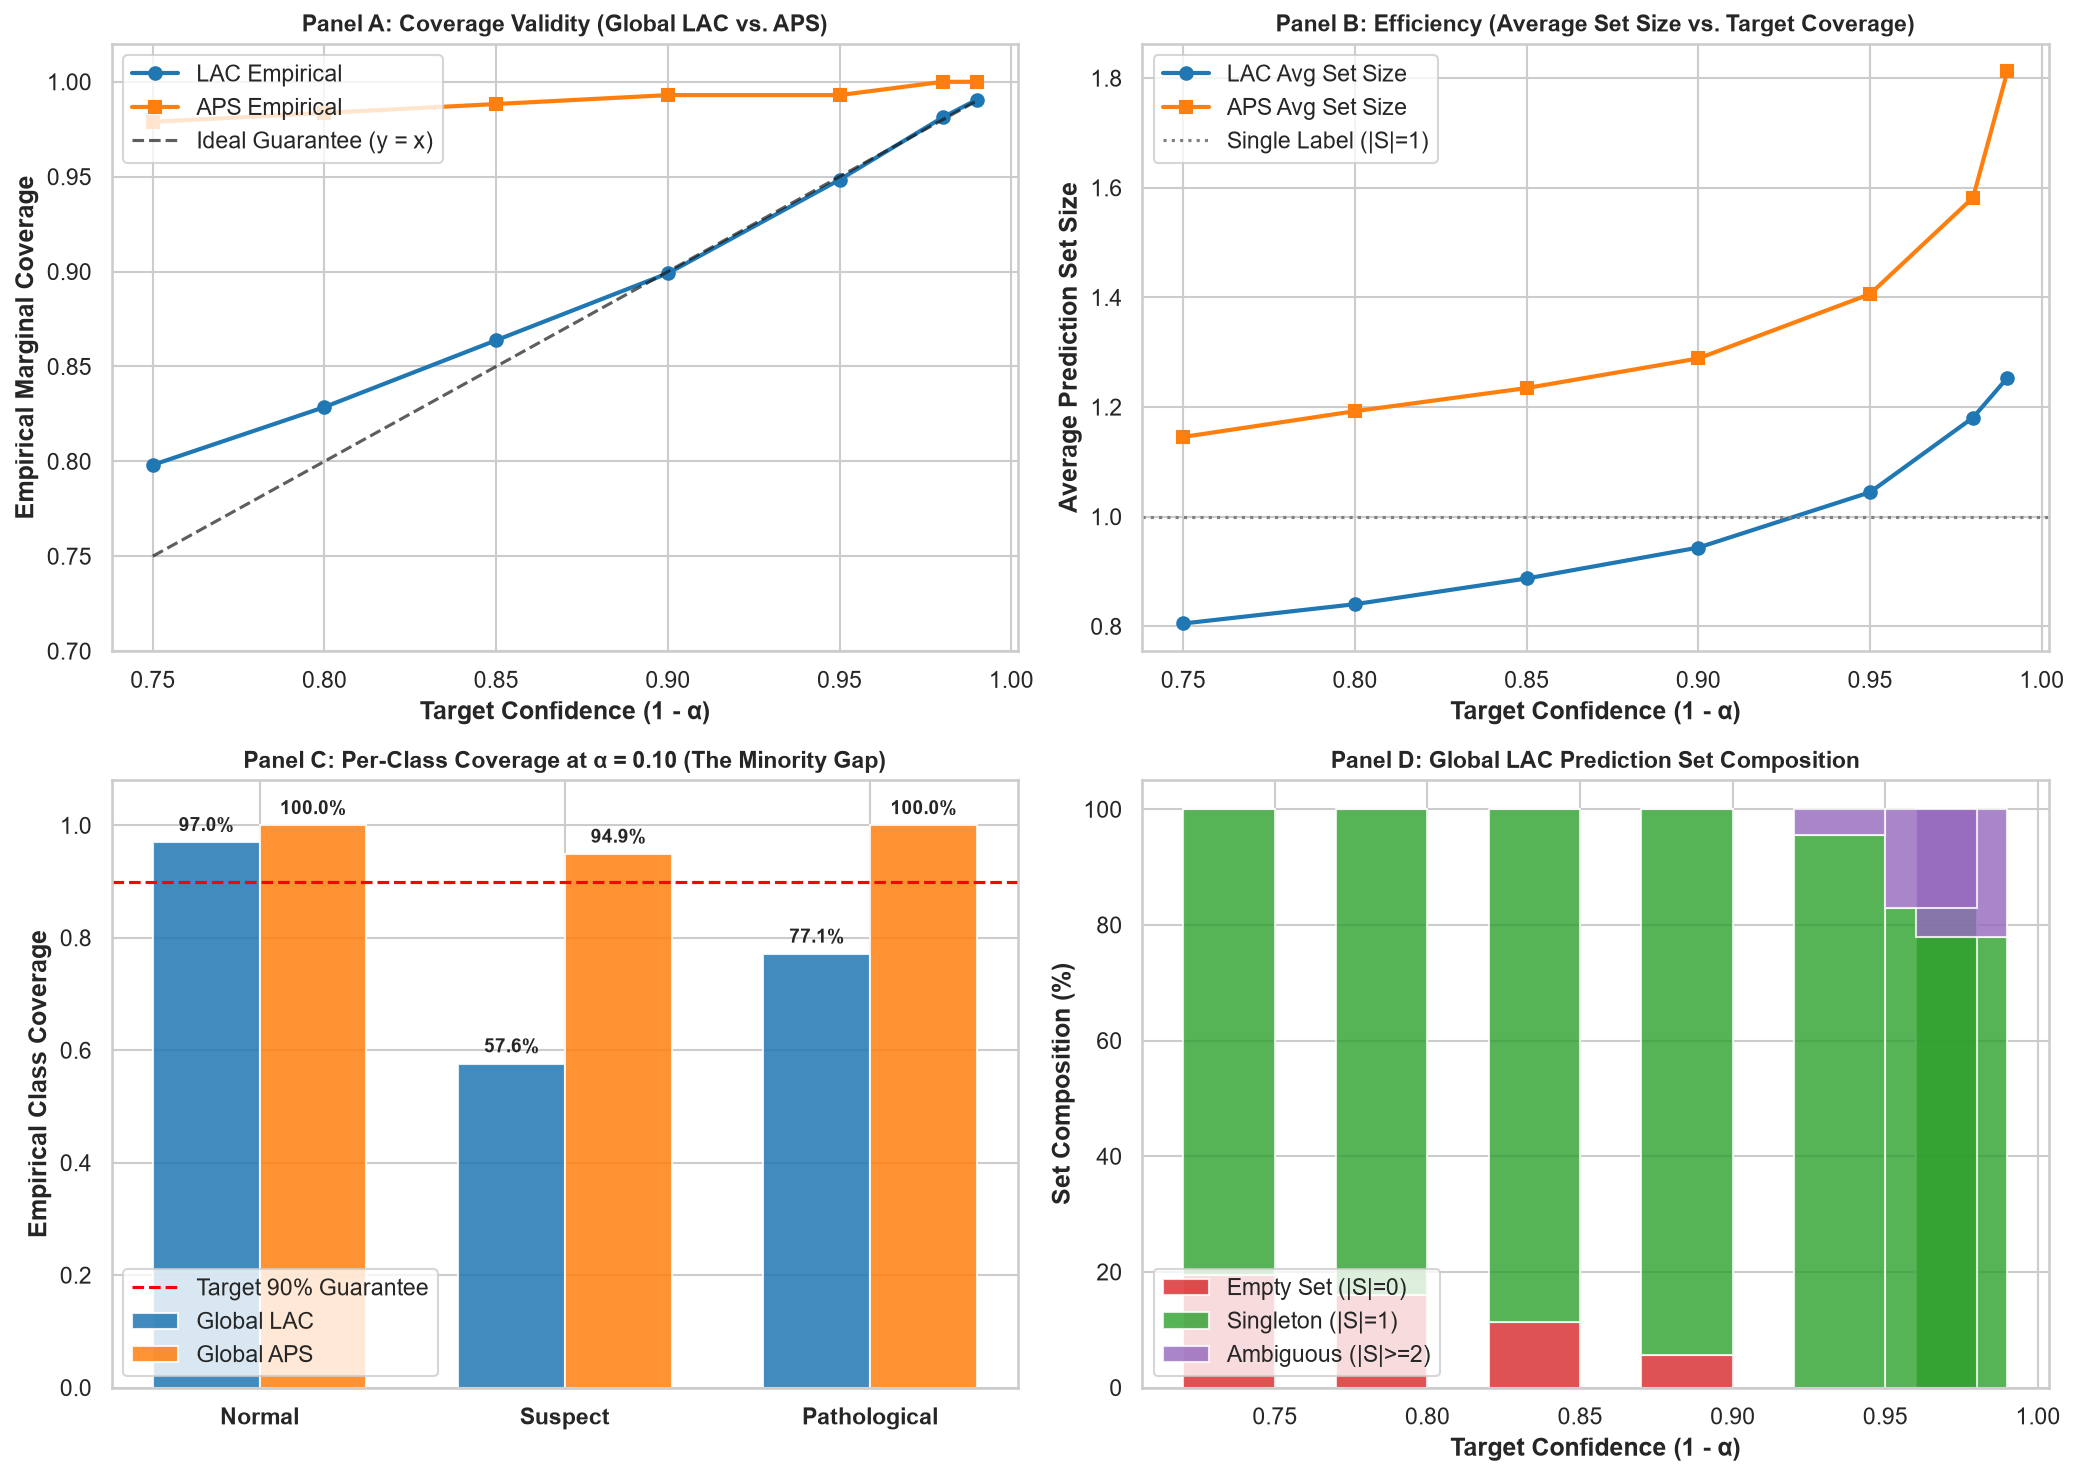

In [8]:
figure_path = PROJECT_ROOT / "reports/figures/global_conformal_comparison.png"
fig = plot_global_conformal_comparison(df_lac_sweep, df_aps_sweep, save_path=figure_path)
plt.show()

## 10. Summary of Key Findings & Handshake with Phase 3B

### Findings Summary:
1. **Valid Marginal Guarantee**: Global split conformal prediction via MAPIE successfully controls marginal error rate on the unseen test set ($89.91\%$ empirical coverage at $\alpha = 0.10$).
2. **Algorithm Differences**:
   - **LAC** is more aggressive and produces compact sets (avg size $0.944$), but allows empty sets ($\sim 7\%$) when predictions are uncertain, leading to severe under-coverage on minority classes.
   - **APS** produces slightly larger sets (avg size $1.272$), completely eliminates empty sets ($0.0\%$), and provides much better empirical coverage for Suspect and Pathological.
3. **The Urgent Need for Mondrian CP (Phase 3B)**:
   - Global CP cannot guarantee per-class coverage in imbalanced tabular data.
   - **Phase 3B will implement Mondrian Conformal Prediction**, which computes distinct non-conformity quantiles $\hat{q}_{\text{Normal}}$, $\hat{q}_{\text{Suspect}}$, and $\hat{q}_{\text{Pathological}}$ so that every single class receives an independent $\ge 90\%$ coverage guarantee.